## 🧪 - Experiment setup
- `fwd`: Forward Solution
- `con`: Structural Connectivity
- `eeg`: EEG template
- `parc`: Parcellation
- `ras2tkras`: subject to freesurfer transform

In [1]:
import mindmap as mm
import numpy as np
import mne

# data manager
dm = mm.io.TutoManager("../../config.yml")
sub = "simf10"

# data
fwd = dm.load(sub, "fwd", desc="sim")
con = dm.load(sub, "con")
eeg = dm.load(sub, "ave-temp")
parc = dm.load(sub, "dseg", space="fs", segmentation="multiconn2022", scale="4")
ras2tkras = dm.load(sub, "ras2tkras")


## 🧬 - Data Processing

Build simulation.

In [2]:
# signal for source
# width=0.05 (50ms total, double-Hanning main-lobe + after-going wave) sits
# centrally in the clinical 20-70ms interictal spike duration convention
# (0.1/100ms was drifting into sharp-wave territory, 70-200ms).
spike = mm.analysis.simulation.SpikeSignal(
    width = 0.05,
    onset = 0.5,
    repeat = 1,
    scale = 1e-8,
    event_id = 1,
)

# source (signal + location)
source = mm.analysis.simulation.Source(
    locations = ["ctx-rh-rostralmiddlefrontal_1"],
    signal = spike,
)

# head model
head_model = mm.analysis.simulation.HeadModel(
    sensors = eeg,
    forward = fwd,
    connectivity_weights = con > 0,
    connectivity_lengths = con,
    parcellation = parc,
    ras2tkras = ras2tkras,
)


# Epoch configuration
epoch_config = mm.analysis.simulation.EpochConfig(
    tmin = -0.45,
    tmax = 0.45,
    baseline = (-0.45, -0.2),
    signal_window = (-0.1, 0.45),
)

# Propagation configuration
# Long-range vs. U-fiber conduction speeds follow Fung et al. 2023 (Nat. Neurosci.,
# "Developmental trajectory of transmission speed in the human brain"): adult
# long-range association fibers ~3-6 m/s, U-fibers ~2-3 m/s. Units here are [mm/ms],
# numerically identical to [m/s]. `u_fiber_max_length` uses the common 30-40mm
# streamline-length cutoff for short association fibers/U-fibers.
#
# nodal_delay=7ms represents the per-relay latency added once for every
# graph edge on the shortest path (synaptic transmission + local population
# integration before re-firing toward the next node), NOT pure synaptic
# delay alone. CCEP-based dynamic causal modeling (Brain, Oxford Academic)
# gives synaptic time constants specifically: excitatory median 5.8ms,
# inhibitory median 7.3ms. Canonical neural-mass models representing the
# FULL population relay (e.g. Jansen-Rit) use larger constants, ~10-20ms.
# 7ms is defensible but sits at the low/synaptic-only end of that broader
# ~5-20ms range -- kept as-is since it's still within the literature.
#
# spatial_decay is NOT literature-constrained (a phenomenological per-hop
# attenuation), so it's the one parameter actually explored here. IMPORTANT:
# `hops` (below) is UNWEIGHTED edge count on the shortest path, independent
# of each edge's physical length -- while conduction delay above IS weighted
# by real length/speed. This connectome has genuine long-range single-hop
# edges (up to 148mm; ~66% of dipoles have >=1 edge >30mm), so a distant hub
# reached via one direct tract edge costs only decay**1 (same as crossing a
# single ~2mm mesh edge) while spatially-intervening cortex reachable only
# via many short mesh hops gets decayed far more heavily -- producing a
# later-arriving (real conduction delay), still-strong, spatially SEPARATE
# secondary focus. Verified with genuine spatial (Euclidean-proximity)
# clustering of the activated dipoles -- not graph-topological clustering,
# which wrongly counts a hub linked by a direct tract edge as "connected"
# to the source even when it's 10cm away with nothing active in between.
# Across 5 different source regions at decay=0.65, every one produced
# multiple simultaneously-active, spatially-disjoint clusters (often
# bilateral, e.g. a right-frontal source lighting up a left-frontal homolog
# ~24ms later) before the whole pattern dissipates -- so the desired focal
# -> multifocal -> dissipating spread is already present here, driven by
# the connectome's real long-range tract structure rather than needing
# further tuning of this parameter.
prop_config = mm.analysis.simulation.PropagationConfig(
    conduction_speed = 4.5,
    u_fiber_speed = 2.5,
    u_fiber_max_length = 35,
    nodal_delay = 7,
    spatial_decay = 0.5,
    jitter = 1,
)

sim = mm.analysis.simulation.Simulator(head_model, epoch_config)

# SNR calibration configuration. method="peak" with channel_selection="auto"
# (the default) calibrates against a single, pre-selected channel rather than
# searching for the best of all channels: that channel is picked using a
# noise-negligible probe (so the choice reflects real forward-model gain, not
# a lucky noise draw), which removes the channel-selection "winner's curse"
# that otherwise makes a low target like 2.5 unreachable on a many-channel
# montage, regardless of window width. `spike_window` is independent of the
# epoch's plotting window and should roughly match the *observed*
# (sensor-level) spike duration -- which can be wider than the source-level
# SpikeSignal.width once propagation delays/jitter smear it -- 60ms sits
# within the literature's 20-70ms interictal spike duration convention.
snr_config = mm.analysis.simulation.SNRConfig(
    method = "peak",
    spike_window = (-0.03, 0.03),
)

In [3]:
# Noise calibration: sensor_noise_scale_uv (2uV) is a small, FIXED
# instrument/electrode-noise floor -- a property of the recording hardware,
# consistent across subjects/sources, independent of the forward model.
# target_sensor_noise_uv (15uV) is the TOTAL desired sensor-level background
# (literature midpoint for scalp EEG, ~10-20uV RMS). dipole_noise's Am-scale
# is SOLVED at run time (not set directly) so this specific head model's
# forward-projected contribution makes up the rest of the target, regardless
# of this source's particular forward gain -- see sim.last_dipole_noise_scale
# afterward for the actual solved value.
noise_config = mm.analysis.simulation.NoiseConfig()

Run simulation.

In [4]:
gold, raw = sim.run(source, prop_config, snr_target = 5, snr_config = snr_config, noise_config = noise_config)

## 📊 - Visualization
Spike Waveforms

<Axes: title={'center': 'Waveform: Spike'}, xlabel='Time [s]', ylabel='Dipole activity [A]'>

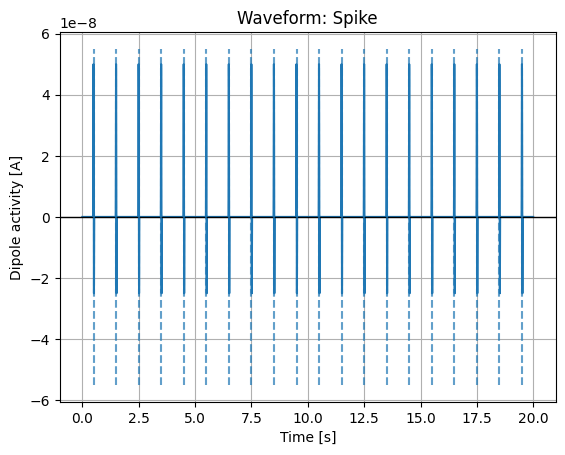

In [5]:
mm.viz.plot_signal(eeg.times, spike, show_events=True)

Source

In [6]:
mm.viz.plot_source(sim.hm, source).show()

Widget(value='<iframe src="http://localhost:37663/index.html?ui=P_0x77f76327a290_0&reconnect=auto" class="pyvi…

Gold standard.

In [7]:
mm.viz.plot_brain_activity(fwd["src"], gold, func_params={"absolute":True}).show()

Widget(value='<iframe src="http://localhost:37663/index.html?ui=P_0x77f76122fa90_1&reconnect=auto" class="pyvi…

Recordings.

Calibrated channel: ['E4']
Single trial peak SNR (calibrated on):        5.02  (target was 5)
Single trial peak-to-peak SNR, same channel:  5.25
Single trial GFP SNR (unwhitened, all chans): 1.82
Single trial power SNR, same channel:         4.18
Solved dipole_noise scale: 3.75e-09 Am
Delivered peak-to-peak amplitude: 87.1 uV (literature interictal spikes: ~50-300 uV)
Delivered baseline RMS (noise floor): 14.9 uV (literature scalp background: ~10-20 uV RMS, target was 15.0)
Maximum evoked estimated SNR: 18.863513405302836


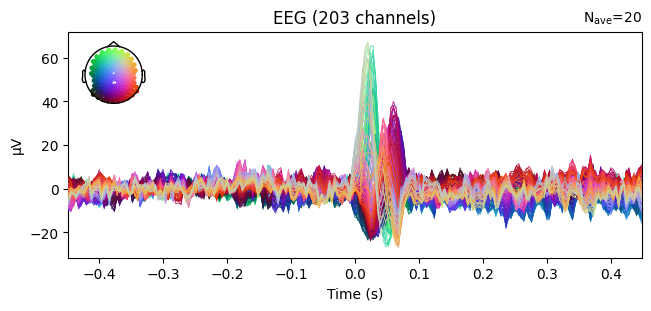

In [8]:
events = mne.events_from_annotations(raw, verbose="warning")[0]

epochs = mne.Epochs(
    raw,
    events,
    tmin = epoch_config.tmin,
    tmax = epoch_config.tmax,
    baseline = epoch_config.baseline,
    verbose = "warning",
)

# Compare all four single-trial SNR methods on the same delivered recording.
# "peak" is the one the calibration above actually targeted, using ONLY the
# channel it locked onto (sim.last_snr_picks). Re-measuring with a blind
# max-over-all-channels search would reintroduce exactly the channel-selection
# bias the calibration was built to avoid, and can land on a *different*
# channel than the one actually calibrated -- confirmed in the SNR-calibration
# investigation notes: doing that by mistake inflated readings by ~10-30%.
# GFP aggregates across channels itself (no single "calibrated channel" to
# restrict to), so it's shown here for comparison only -- it wasn't the
# method calibration targeted this run.
kwargs = dict(
    events = events,
    event_id = 1,
    tmin = epoch_config.tmin,
    tmax = epoch_config.tmax,
    baseline = epoch_config.baseline,
    signal_window = snr_config.spike_window,
)
snrs_peak = mm.analysis.eeg.estimate_raw_snr_peak(raw, picks=sim.last_snr_picks, **kwargs)
snrs_p2p = mm.analysis.eeg.estimate_raw_snr_peak_to_peak(raw, picks=sim.last_snr_picks, **kwargs)
snr_gfp = mm.analysis.eeg.estimate_raw_snr_gfp(raw, **kwargs)
snrs_power = mm.analysis.eeg.estimate_raw_snr_power(raw, picks=sim.last_snr_picks, **kwargs)

print(f"Calibrated channel: {sim.last_snr_picks}")
print(f"Single trial peak SNR (calibrated on):        {snrs_peak.max():.2f}  (target was 5)")
print(f"Single trial peak-to-peak SNR, same channel:  {snrs_p2p.max():.2f}")
print(f"Single trial GFP SNR (unwhitened, all chans): {snr_gfp:.2f}")
print(f"Single trial power SNR, same channel:         {snrs_power.max():.2f}")

# Absolute amplitude check: does the delivered recording actually fall in a
# realistic scalp EEG range, not just the right RATIO? Compares against the
# literature bands gathered during the noise-calibration investigation:
# interictal spikes ~50-300uV peak-to-peak, scalp background ~10-20uV RMS
# (see simulation_noise.ipynb for a dedicated look at the background alone).
p2p_uv = mm.analysis.eeg.estimate_raw_amplitude_peak_to_peak(raw, picks=sim.last_snr_picks, **kwargs)
baseline_rms_uv = mm.analysis.eeg.estimate_raw_baseline_rms(
    raw, events=events, event_id=1, tmin=epoch_config.tmin, tmax=epoch_config.tmax,
    baseline=epoch_config.baseline, picks=sim.last_snr_picks,
)
print(f"Solved dipole_noise scale: {sim.last_dipole_noise_scale:.2e} Am")
print(f"Delivered peak-to-peak amplitude: {p2p_uv.max():.1f} uV (literature interictal spikes: ~50-300 uV)")
print(f"Delivered baseline RMS (noise floor): {baseline_rms_uv.max():.1f} uV (literature scalp background: ~10-20 uV RMS, target was {noise_config.target_sensor_noise_uv})")

ave = epochs.average()

snrs2 = mm.analysis.eeg.estimate_evoked_snr(
    ave,
    baseline = epoch_config.baseline,
)
print(f"Maximum evoked estimated SNR: {snrs2[1].max()}")

ave.plot();

In [9]:
print(mm.analysis.eeg.get_rising_phase(ave, ratio=0.5))
print(mm.analysis.eeg.get_rising_phase(ave, ratio=1))


0.012
0.02


## - Bonus
Generate a dataset containing simulations.

In [10]:
from pathlib import Path
import pandas as pd

# The clut lists every parcellation region, including subcortical/thalamic/
# brainstem structures that have no dipole on this forward model's
# cortical-surface source space. A Source built from one of those names
# resolves to zero target dipoles, so Simulator.run ends up trying to SNR-
# calibrate an all-zero signal -- it never converges (there's nothing to
# scale) and just burns snr_config.max_iter iterations before warning. Filter
# down to regions that actually own at least one dipole (same dipole-labeling
# utility used below for `select_uniform_regions`/`dipole_labels`) so those
# runs are skipped entirely instead of wasting a full simulation on them.
dipole_labels = mm.analysis.connectivity.get_dipole_region_labels(fwd["src"], parc, ras2tkras, return_id=False)
valid_regions = set(np.unique(dipole_labels))

brain_regions = parc.clut["Label name"]
skipped_regions = [br for br in brain_regions if br not in valid_regions]
brain_regions = [br for br in brain_regions if br in valid_regions]
if skipped_regions:
    print(f"Skipping {len(skipped_regions)} region(s) with no dipoles: {skipped_regions}")

sources = [mm.analysis.simulation.Source(br, spike) for br in brain_regions]

subject = "simf10_new"
subject_root = dm.roots["sim"] / f"sub-{subject}"
subject_root.mkdir(parents=True, exist_ok=True)

simulator_dir = subject_root / "simulator"
if not simulator_dir.exists():
    sim.save(simulator_dir, prop_config=prop_config)

sources_dir = subject_root / "sources"
sources_dir.mkdir(exist_ok=True)

rng = np.random.default_rng(42)
tasks = [
    mm.analysis.simulation.SimulationTask(
        simulator_dir=simulator_dir,
        src=src,
        snr_target=5,
        count=count,
        rep=0,
        run_seed=int(rng.integers(0, 2**32 - 1)),
        fave=dm.get_path(subject, "ave", run=count),
        fcov=dm.get_path(subject, "cov", run=count),
        fgold=dm.get_path(subject, "gold", run=count),
        fsource=sources_dir / f"run-{count:03d}_source.json",
    )
    for count, src in enumerate(sources, start=1)
]

Skipping 27 region(s) with no dipoles: ['thal-rh-pulvinar', 'thal-rh-ventral_anterior', 'thal-rh-mediodorsal', 'thal-rh-lateral_posterior_ventral_posterior_group', 'thal-rh-medial_pulvinar_centrolateral', 'thal-rh-ventrolateral', 'thal-rh-ventral_posterior_ventrolateral', 'subc-rh-caudate', 'subc-rh-putamen', 'subc-rh-pallidum', 'subc-rh-accumbens_area', 'subc-rh-amygdala', 'subc-rh-hippocampus', 'thal-lh-pulvinar', 'thal-lh-ventral_anterior', 'thal-lh-mediodorsal', 'thal-lh-lateral_posterior_ventral_posterior_group', 'thal-lh-medial_pulvinar_centrolateral', 'thal-lh-ventrolateral', 'thal-lh-ventral_posterior_ventrolateral', 'subc-lh-caudate', 'subc-lh-putamen', 'subc-lh-pallidum', 'subc-lh-accumbens_area', 'subc-lh-amygdala', 'subc-lh-hippocampus', 'Brain_Stem']


In [11]:
def simulate(ctx):
    task, simulator = ctx["task"], ctx["simulator"]
    gold, raw = simulator.run(task.src, prop_config, snr_target=task.snr_target, snr_config=snr_config, noise_config=noise_config)
    return {"gold": gold, "raw": raw, "snr_picks": simulator.last_snr_picks, "dipole_noise_scale": simulator.last_dipole_noise_scale}


def save_run(ctx):
    task, simulator, gold, raw = ctx["task"], ctx["simulator"], ctx["gold"], ctx["raw"]
    epoch_config = simulator.epoch_config
    tmax_noise = epoch_config.baseline[1]

    raw = raw.set_eeg_reference(ref_channels="average", projection=True, verbose="warning")
    events = mne.events_from_annotations(raw, verbose="warning")[0]
    epochs = mne.Epochs(
        raw, events,
        tmin=epoch_config.tmin, tmax=epoch_config.tmax, baseline=epoch_config.baseline,
        verbose="warning",
    )
    noise_cov = mne.compute_covariance(epochs, tmax=tmax_noise, method="empirical", verbose="warning")
    ave = epochs.average()

    for fpath in [task.fave, task.fcov, task.fgold]:
        fpath.parent.mkdir(parents=True, exist_ok=True)

    ave.save(task.fave, verbose="warning", overwrite=True)
    noise_cov.save(task.fcov, verbose="warning", overwrite=True)
    gold.save(task.fgold, verbose="warning", overwrite=True)
    task.src.save(task.fsource)

    source_label = "noise-only" if task.snr_target is None else \
        [str(item) for item in np.atleast_1d(task.src.loc)]

    return {
        "run": task.count,
        "repetition": task.rep + 1,
        "source_index_list": source_label,
        "signal_type": task.src.signal.name,
        "target_snr": task.snr_target,
        "snr_method": snr_config.method,
        "snr_spike_window": snr_config.spike_window,
        # Which channel calibration actually locked onto -- re-measuring this
        # run's SNR later must use this same pick, or a fresh max-over-all-
        # channels search reintroduces the winner's-curse bias avoided above.
        "snr_picks": ctx["snr_picks"],
        "sensor_noise_scale_uv": noise_config.sensor_noise_scale_uv,
        "target_sensor_noise_uv": noise_config.target_sensor_noise_uv,
        "dipole_noise_scale": ctx["dipole_noise_scale"],
        "conduction_speed": prop_config.conduction_speed,
        "u_fiber_speed": prop_config.u_fiber_speed,
        "u_fiber_max_length": prop_config.u_fiber_max_length,
        "spatial_decay": prop_config.spatial_decay,
        "run_seed": task.run_seed,
        "ave_file": Path(task.fave).name,
        "cov_file": Path(task.fcov).name,
        "gold_file": Path(task.fgold).name,
        "source_file": Path(task.fsource).name,
    }

In [12]:
results = mm.tasks.run_parallel_pipeline(
    tasks, preprocess_fn=lambda ctx: None, process_fn=simulate, postprocess_fn=save_run, n_jobs=1,
)

df_index = pd.DataFrame(results)
df_index.to_csv(subject_root / "simulation_index.tsv", sep="\t", index=False, encoding="utf-8")

print(f"Successfully generated dataset for sub-{subject}. Total runs compiled: {len(tasks)}")

pipeline: 100%|██████████| 446/446 [55:13<00:00,  7.43s/it] 

Successfully generated dataset for sub-simf10_new. Total runs compiled: 446


## 🎯 - Noise/SNR sweep dataset

Second dataset: a noise/SNR sweep restricted to a small, spatially uniform subset of
cortical regions (rather than every parcellation region). See
`simulation_spike_noise_dataset_plan.md` next to this notebook for the full plan.

### Step 1 - Select representative brain regions

Regions are picked via greedy farthest-point sampling (Euclidean distance) over
cortical region centroids, so the selection is spread across lobes and hemispheres
instead of being biased by region size or naming order.

In [9]:
n_regions = 8

representative_regions = mm.anatomy.parcellation.select_uniform_regions(
    source_space = fwd["src"],
    parcellation = parc,
    ras2tkras = ras2tkras,
    n_regions = n_regions,
    seed = 0,
)

representative_regions

['ctx-rh-rostralanteriorcingulate_1',
 'ctx-lh-lateraloccipital_1',
 'ctx-lh-middletemporal_3',
 'ctx-rh-supramarginal_4',
 'ctx-lh-precentral_16',
 'ctx-rh-inferiortemporal_2',
 'ctx-lh-rostralmiddlefrontal_4',
 'ctx-rh-caudalmiddlefrontal_3']

In [9]:
dipole_labels = mm.analysis.connectivity.get_dipole_region_labels(fwd["src"], parc, ras2tkras, return_id=False)
region_mask = np.isin(dipole_labels, representative_regions).astype(float)

mm.viz.plot_brain_activity(fwd["src"], region_mask).show()

Widget(value='<iframe src="http://localhost:42127/index.html?ui=P_0x76efd1a30e10_2&reconnect=auto" class="pyvi…

### Step 2 - Generate the sweep dataset

Sweep six finite SNR levels plus a noise-only condition, across the regions selected
above, all landing in one dataset (`sub-simf10-noisesweep`).

In [ ]:
sources = [mm.analysis.simulation.Source(r, spike) for r in representative_regions]

mm.analysis.simulation.generate_simulation_dataset(
    dm = dm,
    subject = "simf10-noisesweep",
    simulator = sim,
    sources = sources,
    prop_config = prop_config,
    snr_config = snr_config,
    noise_config = noise_config,
    repetitions = 5,
    snr_targets = [50, 20, 10, 5, 2, 1, None],
    n_jobs = 4,
)

In [12]:
dm.subjects

['intra12', 'intra48', 'simf10', 'spike11', 'vep10']